# Contextual Quantum Neural Networks for Stock Price Prediction — a reproduction walkthrough

Paper: S. Mourya, H. Leipold, B. Adhikari, *Contextual Quantum Neural Networks
for Stock Price Prediction*, Scientific Reports 16:34413 (2026),
[arXiv:2503.01884](https://arxiv.org/abs/2503.01884).

This notebook explains the paper's method, reproduces its core mechanics live
on a CPU, and then places the stored multi-seed results (1900 runs) next to
classical reference models. It is the entry point to the reproduction; the
full record is in `README.md` and `LOG.md`.

**What runs live (about 9.5 minutes on a laptop CPU):** the paper's QSTL circuit
with its own hyperparameters on two assets and three seeds, a
context-preserving variant, the classical baselines B0–B3, and a small MerLin
photonic model. **What is loaded from stored runs:** every multi-seed sweep
(S1–S12, P1, Phase 5). Each loaded table names its source file.

Contents

1. Problem statement and the paper's claims
2. Data, splits, metrics and evaluation protocol
3. The method in equations
4. Known-answer sanity checks
5. Model walkthrough
6. Small live experiment
7. Headline reproduction result
8. Comparison with classical baselines
9. Controls and ablations
10. Robustness and uncertainty
11. Photonic adaptation (MerLin)
12. Claim-level conclusion

In [1]:
import copy
import json
import logging
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Image, display
from scipy import stats

PAPER_DIR = Path.cwd()
if not (PAPER_DIR / "lib" / "runner.py").exists():
    raise RuntimeError("Start Jupyter inside papers/QNN_STOCK so the paper's lib/ is importable.")
REPO_ROOT = PAPER_DIR.parents[1]
for path in (PAPER_DIR, REPO_ROOT):
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))

from runtime_lib.config import deep_update

from lib.baselines import counts_table, fit_baselines, frequency_table
from lib.circuits import apply_ansatz, n_params
from lib.data import build_tasks, joint_distribution
from lib.metrics import sequence_metrics
from lib.model import ContextualTask
from lib.photonic_merlin import fit_photonic_model
from lib.statevector import apply_1q, apply_cswap, basis_state, probabilities
from lib.training import qstl_circuit_factory, train_qstl

logging.getLogger("lib").setLevel(logging.WARNING)
warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.width", 160)
pd.set_option("display.precision", 4)
plt.rcParams["figure.dpi"] = 80  # keeps the stored notebook small

RESULTS = PAPER_DIR / "results"
# One color per model family, used in every figure.
COLORS = {
    "QSTL (paper circuit)": "#1f77b4",
    "context-preserving (E11)": "#2ca02c",
    "B0 frequency": "#7f7f7f",
    "B2 logistic": "#ff7f0e",
    "B3 MLP": "#8c564b",
    "photonic (MerLin)": "#9467bd",
    "target": "#d62728",
}
DEFAULTS = json.loads((PAPER_DIR / "configs" / "defaults.json").read_text(encoding="utf-8"))


def config(overlay_name=None, **overrides):
    # Resolve a named config the same way implementation.py does: defaults, then the overlay.
    cfg = copy.deepcopy(DEFAULTS)
    if overlay_name is not None:
        overlay = json.loads((PAPER_DIR / "configs" / overlay_name).read_text(encoding="utf-8"))
        cfg = deep_update(cfg, overlay)
    return deep_update(cfg, overrides)


def paired_interval(differences):
    # Paired-by-seed mean difference and 95 % t interval (the Phase 5 protocol).
    d = np.asarray(differences, dtype=float)
    half = stats.t.ppf(0.975, len(d) - 1) * d.std(ddof=1) / np.sqrt(len(d))
    return d.mean(), d.mean() - half, d.mean() + half


print("torch", torch.__version__, "| numpy", np.__version__)

torch 2.12.1+cpu | numpy 2.5.4


## 1. Problem statement and the paper's claims

The paper turns a daily price series into up/down symbols and asks a quantum
circuit to output the probability of tomorrow's move given the last $T = 3$
moves (the *context*). Its distinctive idea is the **quantum batch gradient
update (QBGU)**: instead of feeding training windows one by one, the whole
empirical context distribution is loaded as one superposition, and a single
SWAP-test fidelity against the target joint distribution is the loss. A
multi-task version (**QMTL**) shares one circuit block across assets and adds a
small asset-specific block.

**Research question of this reproduction.** On public daily prices for the
paper's tickers:

1. Does the QBGU-trained circuit (QSTL) learn the next-move distribution so that,
   used as the paper uses it at prediction time (one context in, prediction
   qubit out), it is at least as good on held-out data as classical models
   with the same information?
2. Does QMTL improve on QSTL with half the parameters per asset?

**What would weaken the claims.** A per-context test log-loss above the
frequency table B0 or logistic regression B2 with a paired 95 % interval that
excludes 0; QMTL no lower than a QSTL of equal size and training budget.

| ID | Claim in the paper | Evidence in the paper | Tested here by |
|---|---|---|---|
| C1 | QSTL learns the next-day conditional | Fig. 13, Table 1 | §6, §7, §8 |
| C2 | QMTL beats QSTL with half the parameters | Table 1, Fig. 14 | §7, §8 |
| C3 | QMTL converges faster | Fig. 16 | §8 |
| C4 | One QBGU step equals full-batch SGD (Eq. 18–20) | derivation | §9 |
| C5 | The SWAP-test loss learns where MSE does not | Fig. 17 | §9 |
| C6 | A trained HEA loader prepares the context state | Fig. 11–12 | §9 |
| C7 | QMTL scales to 4 and 8 assets | Fig. 15, 18, 21 | §8 |
| C8 | $d = 4$ levels, $T = 2$ distributions align | Fig. 19 | §8 |
| C9 | Depolarizing noise degrades faster than readout noise | Fig. 22 | not run |
| C10 | Portfolio loading / downstream quantum advantage | discussion | out of scope |

Categories used below: **reproduction** (the paper's experiment, our data),
**control** (a comparison that separates the paper's explanation from an
alternative), **robustness** (other seeds, sizes, preprocessing), and
**extension** (not in the paper, labelled as such).

## 2. Data, splits, metrics and evaluation protocol

**Data (`substitute-data`).** The authors' data is available on request; this
reproduction uses public CC0 Zenodo daily prices for the same tickers, which
agree with Yahoo Finance exports. `Close` prices up to 2020-09-25 (AAPL then
has the paper's 10,033 prices). Location: `data/QNN_STOCK/sp500_daily_prices_zenodo/`.

**Preprocessing.** Optional moving average (raw = window 1, MA5 = 5-day
average, both used in the paper), one-step differences, sign → {down 0, up 1},
windows of $T$ context moves plus the next move.

**Splits.** Chronological: the first 80 % of windows train, the last 20 % test.
The baselines select their hyperparameters on the last 12.5 % of the training
windows and are refit on all training windows. Quantum models do no selection:
the final epoch is reported, as in the paper. **The test split is never used to
choose anything.**

**Metric.** The paper reports KL divergence on the training distribution. We
report it too (§7), and add the **test log-loss of the per-context
prediction** $-\frac{1}{N}\sum_n \log q(o_n \mid c_n)$ (lower is better,
$\ln 2 = 0.693$ is a coin flip) as the primary metric, because that is how the
model is used to predict.

**Seeds and uncertainty.** Seeds 42–46 per configuration; differences are
paired by seed and reported with a 95 % $t$ interval. An interval containing 0
means "not distinguishable", which is not the same as "equal".

In [2]:
data_rows, tasks_by_setting = [], {}
for setting, window in (("raw", 1), ("MA5", 5)):
    cfg = config(dataset={"tickers": ["AAPL", "GOOGL"], "moving_average_window": window})
    tasks_by_setting[setting] = {t.ticker: t for t in build_tasks(cfg)}
    for t in tasks_by_setting[setting].values():
        data_rows.append({
            "setting": setting, "ticker": t.ticker, "first date": t.first_date, "last date": t.last_date,
            "prices": t.n_prices, "train windows": len(t.train_windows), "test windows": len(t.test_windows),
            "train share up": t.train_windows[:, -1].mean(), "test share up": t.test_windows[:, -1].mean(),
        })
pd.DataFrame(data_rows)

,setting,ticker,first date,last date,prices,train windows,test windows,train share up,test share up
0,raw,AAPL,1980-12-12,2020-09-25,10033,8023,2006,0.4876,0.5244
1,raw,GOOGL,2004-08-19,2020-09-25,4055,3240,811,0.5198,0.5327
2,MA5,AAPL,1980-12-12,2020-09-25,10033,8020,2005,0.5256,0.5756
3,MA5,GOOGL,2004-08-19,2020-09-25,4055,3237,810,0.5644,0.5963


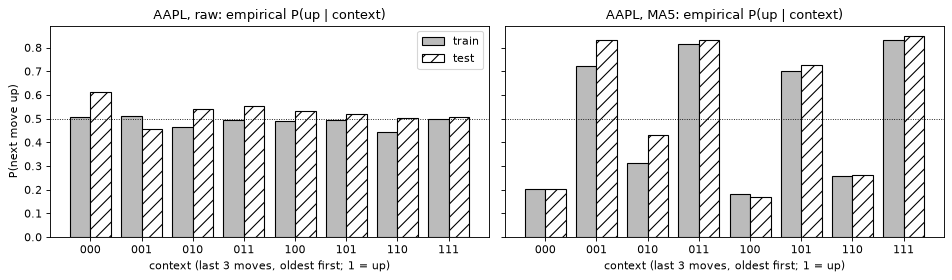

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
labels = [format(c, "03b") for c in range(8)]
for ax, setting in zip(axes, ("raw", "MA5")):
    t = tasks_by_setting[setting]["AAPL"]
    for split, windows, offset, hatch in (("train", t.train_windows, -0.2, None), ("test", t.test_windows, 0.2, "//")):
        joint = joint_distribution(windows, 2, 2)
        p_up = joint[:, 1] / joint.sum(axis=1)
        ax.bar(np.arange(8) + offset, p_up, width=0.4, label=split, color="#bbbbbb" if split == "train" else "white",
               edgecolor="black", hatch=hatch)
    ax.axhline(0.5, color="black", lw=0.8, ls=":")
    ax.set_xticks(range(8), labels)
    ax.set_xlabel("context (last 3 moves, oldest first; 1 = up)")
    ax.set_title(f"AAPL, {setting}: empirical P(up | context)")
axes[0].set_ylabel("P(next move up)")
axes[0].legend()
plt.tight_layout()
plt.show()

**Observation.** On raw daily moves $P(\text{up} \mid c)$ stays close to 0.5 in
every context, in train and test. With the 5-day average the next move depends
strongly on the context (momentum), and the train and test tables agree.

**Inference.** Raw daily direction carries almost no learnable signal, so on raw
data every model sits near $\ln 2$ and comparisons carry little information.
MA5 is the setting where a difference between models can show.

**Remaining uncertainty.** The paper does not state its date ranges or which
experiments use the moving average; our targets are not the paper's targets
(our raw AAPL table is flatter than the paper's Fig. 13).

## 3. The method in equations

Registers: $T$ context qubits (big-endian, oldest move first) and one
prediction qubit. With $P(c)$ the context distribution and $P(c, o)$ the joint
distribution of context and next move on the training windows:

$$
\lvert \psi_\text{in} \rangle = \sum_c \sqrt{P(c)}\,\lvert c \rangle \lvert 0 \rangle,
\qquad
\lvert \psi_\text{target} \rangle = \sum_{c,o} \sqrt{P(c,o)}\,\lvert c, o \rangle .
$$

A parameterized circuit $U(\theta)$ acts on $\lvert \psi_\text{in} \rangle$. A
SWAP test against the target returns ancilla 0 with probability
$P(0) = \tfrac{1}{2}(1 + F)$, $F = \lvert \langle \psi_\text{target} \vert U(\theta) \vert \psi_\text{in} \rangle \rvert^2$,
and the loss is $L = 1 - P(0) = \tfrac{1}{2}(1 - F)$ (Eq. 13–14), estimated
from 10,000 shots and minimized with SPSA (lr 0.1, perturbation 0.01, 3000
epochs).

**Two ways to read the trained circuit.**

* *Joint readout* (the training target): measure all qubits of
  $U \lvert \psi_\text{in} \rangle$ and compare the distribution with $P(c, o)$.
  This is what Table 1 and Fig. 13 evaluate.
* *Per-context readout* (prediction): load one context, $U \lvert c \rangle \lvert 0 \rangle$,
  and read the prediction qubit: $q(o \mid c)$. This is how a new day is
  predicted, so held-out log-loss uses it.

The two agree only if the circuit keeps each context in place. The
**context retention** $\lVert (\langle c \rvert \otimes I)\, U \lvert c, 0 \rangle \rVert^2$
measures that; it is 1 for a circuit that only uses the context as control and
$1/2^T = 0.125$ on average for one that spreads it uniformly.

**Circuits.** QSTL (paper): 4 layers of RY, RZ on all 4 qubits plus a ring of
CNOTs, 32 parameters. QMTL: one shared layer plus one label-controlled
asset-specific block (RY, RZ, Fig. 7), 16 parameters per asset. Extension E11:
rotations on the prediction qubit controlled by the context bits (interaction
order 1: 4 parameters), so $q(\text{up} \mid c) = \sin^2(a_c / 2)$ with $a_c$
linear in the context bits.

**Classical references.** B0 frequency table (8 free probabilities), B1
uniform / marginal, B2 logistic regression on the context bits (4 weights), B3
small MLP (16 or 31 parameters), B4 pooled shrinkage across assets.

## 4. Known-answer sanity checks

Before trusting any result, check the pieces against answers known in advance.

1. The analytic SWAP-test statistic $\tfrac{1}{2}(1 + F)$ equals the ancilla
   statistics of the explicit Hadamard–controlled-SWAP–Hadamard circuit.
2. The identity circuit reaches $F = 1$ when the next move is always 0.
3. The frequency table B0 reproduces the training conditional exactly.
4. A circuit that only uses the context as control keeps every context
   (retention 1); a random paper-style circuit does not.

In [4]:
rng = np.random.default_rng(0)
joint = rng.random((8, 2)); joint /= joint.sum()
task = ContextualTask(joint)
theta = rng.uniform(0, 2 * np.pi, n_params(4, 2))
output = apply_ansatz(task.input_state, theta, 4)

n = 9  # ancilla + 4 output qubits + 4 target qubits
state = np.kron(basis_state(0, 1), np.kron(output, task.target_state))
hadamard = np.array([[1, 1], [1, -1]], dtype=np.complex128) / np.sqrt(2)
state = apply_1q(state, hadamard, 0, n)
for qubit in range(4):
    state = apply_cswap(state, 0, 1 + qubit, 5 + qubit, n)
state = apply_1q(state, hadamard, 0, n)
p_zero_circuit = probabilities(state)[: 2 ** (n - 1)].sum()
p_zero_analytic = 0.5 * (1 + task.fidelity(lambda s: apply_ansatz(s, theta, 4)))
assert abs(p_zero_circuit - p_zero_analytic) < 1e-12
print(f"1. SWAP test: explicit circuit P(0) = {p_zero_circuit:.12f}, analytic = {p_zero_analytic:.12f}")

always_down = np.zeros((8, 2)); always_down[:, 0] = 1 / 8
assert abs(ContextualTask(always_down).fidelity(lambda s: s) - 1) < 1e-12
print("2. identity circuit on an always-down target: F = 1")

t = tasks_by_setting["MA5"]["AAPL"]
b0 = frequency_table(t.train_windows, 2, 2, alpha=0.0)
hand_counts = np.zeros((8, 2))
for window in t.train_windows:  # oldest move is the most significant context bit
    hand_counts[window[0] * 4 + window[1] * 2 + window[2], window[3]] += 1
assert np.allclose(b0, hand_counts / hand_counts.sum(axis=1, keepdims=True))
print("3. B0 (no smoothing) equals P(o | c) counted window by window")


def context_retention(circuit, n_contexts=8, levels=2):
    # Probability that U|c,0> is still in context c, for every basis context.
    kept = []
    for c in range(n_contexts):
        probs = probabilities(circuit(basis_state(c * levels, 4))).reshape(n_contexts, levels)
        kept.append(probs[c].sum())
    return np.array(kept)


hea_factory, hea_size = qstl_circuit_factory({"ansatz": "hea", "layers": 4}, 4, 2)
cc_factory, cc_size = qstl_circuit_factory({"ansatz": "context_controlled", "interaction_order": 1}, 4, 2)
hea_keep = context_retention(hea_factory(rng.uniform(0, 2 * np.pi, hea_size)))
cc_keep = context_retention(cc_factory(rng.uniform(0, 2 * np.pi, cc_size)))
assert np.allclose(cc_keep, 1)
print(f"4. retention, context-preserving circuit ({cc_size} params): {cc_keep.round(3)}")
print(f"   retention, random paper circuit ({hea_size} params):       {hea_keep.round(3)}")

1. SWAP test: explicit circuit P(0) = 0.500373974596, analytic = 0.500373974596
2. identity circuit on an always-down target: F = 1
3. B0 (no smoothing) equals P(o | c) counted window by window
4. retention, context-preserving circuit (4 params): [1. 1. 1. 1. 1. 1. 1. 1.]
   retention, random paper circuit (32 params):       [0.061 0.093 0.07  0.107 0.259 0.086 0.109 0.072]


**Observation.** All four checks pass. The analytic SWAP test agrees with the
explicit circuit to $10^{-12}$, which justifies sampling the ancilla from a
binomial instead of simulating 9 qubits. A random paper-style circuit already
moves most of the weight out of each context.

**Claim impact.** None yet: these checks validate components, not the claims.

## 5. Model walkthrough

The two circuits compared most often in this notebook. Left: the paper's
hardware-efficient ansatz (HEA) acting on context and prediction qubits.
Right: the context-preserving extension E11, where the context qubits are
controls only. (Diagrams drawn by `utils/draw_circuit_comparison.py`.)

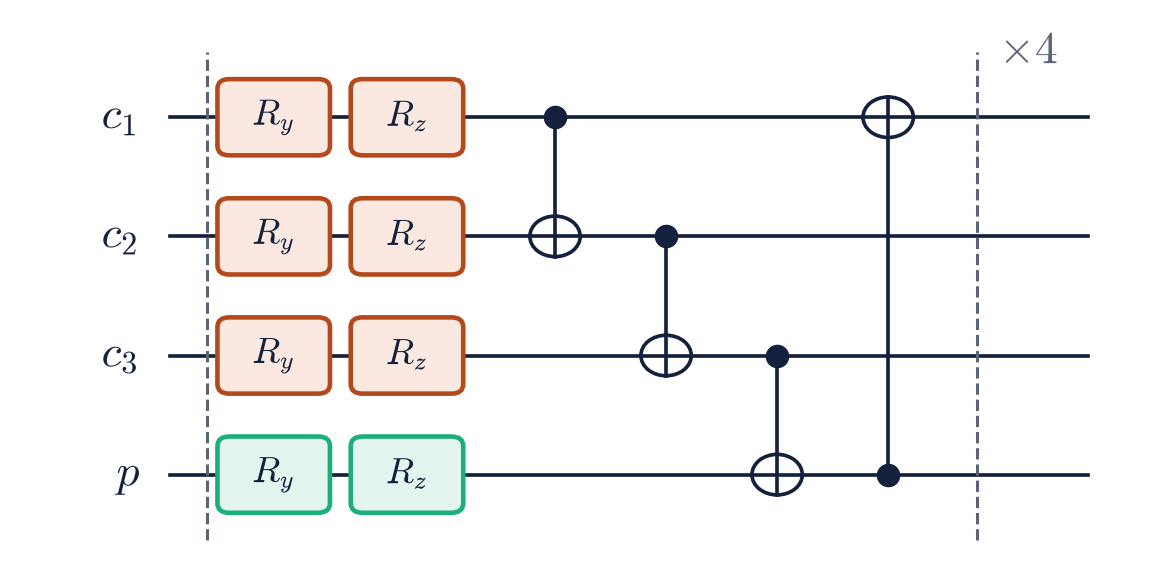

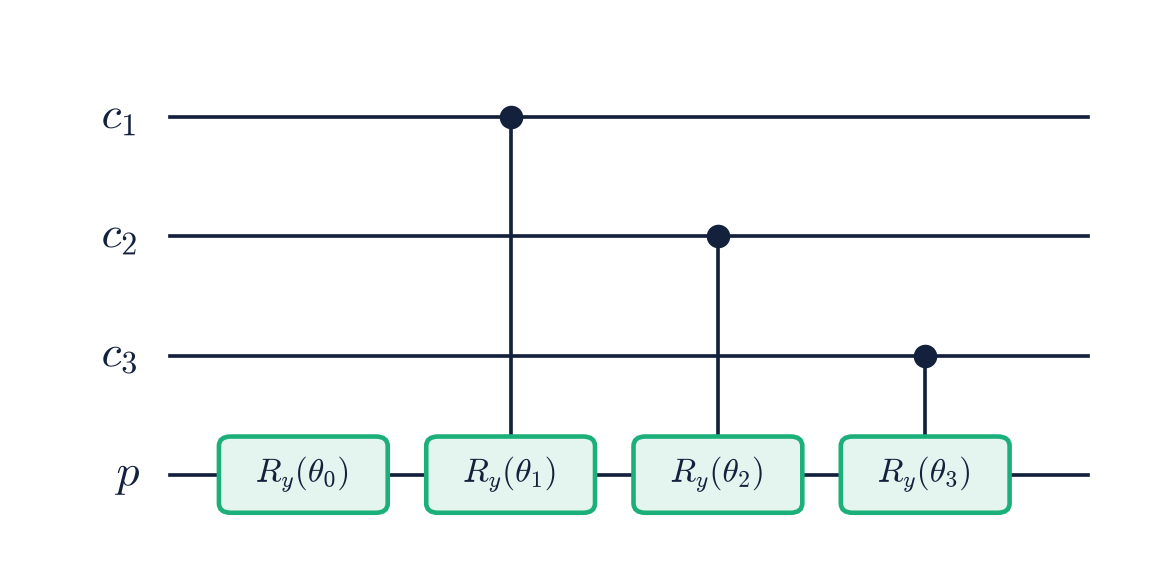

,model,parameters,acts on context qubits
0,"QSTL (paper HEA, 4 layers)",32,yes
1,QSTL 2 layers (QMTL size match),16,yes
2,QMTL per asset (shared + specific),16,yes
3,"context-preserving, order 1 (E11)",4,control only
4,B0 frequency table,8,n/a
5,B2 logistic regression,4,n/a
6,B3 MLP (hidden 6),31,n/a


In [5]:
display(Image(filename=str(RESULTS / "readout_per_context" / "fig_circuit_hea.png"), width=520))
display(Image(filename=str(RESULTS / "readout_per_context" / "fig_circuit_context_preserving.png"), width=520))
pd.DataFrame([
    {"model": "QSTL (paper HEA, 4 layers)", "parameters": hea_size, "acts on context qubits": "yes"},
    {"model": "QSTL 2 layers (QMTL size match)", "parameters": n_params(4, 2), "acts on context qubits": "yes"},
    {"model": "QMTL per asset (shared + specific)", "parameters": 16, "acts on context qubits": "yes"},
    {"model": "context-preserving, order 1 (E11)", "parameters": cc_size, "acts on context qubits": "control only"},
    {"model": "B0 frequency table", "parameters": 8, "acts on context qubits": "n/a"},
    {"model": "B2 logistic regression", "parameters": 4, "acts on context qubits": "n/a"},
    {"model": "B3 MLP (hidden 6)", "parameters": 31, "acts on context qubits": "n/a"},
])

## 6. Small live experiment

Train the paper's QSTL with the paper's hyperparameters (`configs/e3_qstl_ma5.json`:
MA5, $T = 3$, exact context loading, SWAP-test loss, SPSA lr 0.1, perturbation
0.01, 10,000 shots, 3000 epochs) on AAPL and GOOGL for seeds 42–44 (seeds
45–46 are in the stored sweep used in §7.3, to keep the live path under 10
minutes), the
context-preserving extension with the same settings, and the classical
baselines. As in the runner, one random generator per seed is shared by the
two tickers in order, exactly as in the stored sweep S4.

In [6]:
SEEDS = [42, 43, 44]
TICKERS = ["AAPL", "GOOGL"]
qstl_cfg = config("e3_qstl_ma5.json")
cc_cfg = config("e11_qstl_cc1_ma5.json")
live_tasks = {t.ticker: t for t in build_tasks(qstl_cfg)}

live_rows, live_histories, live_circuits = [], {}, {}
start = time.time()
for name, cfg in (("QSTL (paper circuit)", qstl_cfg), ("context-preserving (E11)", cc_cfg)):
    for seed in SEEDS:
        rng = np.random.default_rng(seed)
        for ticker in TICKERS:
            t = live_tasks[ticker]
            task = ContextualTask(joint_distribution(t.train_windows, 2, 2))
            history = []
            circuit, theta = train_qstl(task, cfg["model"], cfg["training"], rng, ticker, history)
            live_histories[(name, seed, ticker)] = pd.DataFrame(history)
            live_circuits[(name, seed, ticker)] = (task, circuit)
            conditional = task.inference_conditional(circuit)
            test = sequence_metrics(t.test_windows, 2, conditional)
            live_rows.append({"model": name, "seed": seed, "ticker": ticker, "parameters": theta.size,
                              "train fidelity F": task.fidelity(circuit), "test log-loss": test["log_loss"],
                              "test accuracy": test["accuracy"]})
print(f"quantum training: {time.time() - start:.0f} s")

start = time.time()
for ticker in TICKERS:
    t = live_tasks[ticker]
    fitted = fit_baselines(t.train_windows, 2, 2, qstl_cfg["baselines"], 42, "cpu")
    for key, label in (("B0_frequency", "B0 frequency"), ("B2_logistic", "B2 logistic"), ("B3_mlp_h6", "B3 MLP")):
        test = sequence_metrics(t.test_windows, 2, fitted[key]["conditional"])
        live_rows.append({"model": label, "seed": 42, "ticker": ticker, "parameters": fitted[key]["n_params"],
                          "train fidelity F": np.nan, "test log-loss": test["log_loss"], "test accuracy": test["accuracy"]})
        live_circuits[(label, ticker)] = fitted[key]["conditional"]
print(f"baselines: {time.time() - start:.0f} s")
live = pd.DataFrame(live_rows)
live.groupby(["model", "ticker"])[["parameters", "train fidelity F", "test log-loss", "test accuracy"]].agg(["mean", "std"]).round(4)

quantum training: 135 s


baselines: 102 s


parameters      train fidelity F         test log-loss         test accuracy        
                                      mean  std             mean     std          mean     std          mean     std
model                    ticker                                                                                     
B0 frequency             AAPL          8.0  NaN              NaN     NaN        0.4750     NaN        0.8150     NaN
                         GOOGL         8.0  NaN              NaN     NaN        0.5142     NaN        0.7938     NaN
B2 logistic              AAPL          4.0  NaN              NaN     NaN        0.4753     NaN        0.8150     NaN
                         GOOGL         4.0  NaN              NaN     NaN        0.5120     NaN        0.7938     NaN
B3 MLP                   AAPL         31.0  NaN              NaN     NaN        0.4750     NaN        0.8150     NaN
                         GOOGL        31.0  NaN              NaN     NaN        0.5142     NaN        0.7938     NaN
QSTL (paper circuit)     AAPL         32.0  0.0           0.9938  0.0041        0.6891  0.1212        0.5278  0.3025
                         GOOGL        32.0  0.0           0.9957  0.0021        0.6918  0.0130        0.6140  0.0224
context-preserving (E11) AAPL          4.0  0.0           0.9997  0.0001        0.4760  0.0003        0.8150  0.0000
                         GOOGL         4.0  0.0           0.9972  0.0023        0.5097  0.0029        0.7938  0.0000

In [7]:
stored_s4 = pd.read_csv(RESULTS / "phase3_s4" / "metrics_long.csv")
stored_s4 = stored_s4[stored_s4.metric == "inference/test/log_loss"]

# Deterministic models (closed form or fixed-seed full-batch fits) must match the stored sweep.
stored_b = stored_s4[(stored_s4.candidate == "e3_baselines_ma5") & (stored_s4.seed == 42)]
baseline_check = live[live.model.str.startswith("B")].merge(
    stored_b.assign(model=stored_b.model.map({"B0_frequency": "B0 frequency", "B2_logistic": "B2 logistic", "B3_mlp_h6": "B3 MLP"}))
    .rename(columns={"asset": "ticker", "value": "stored S4"})[["model", "ticker", "stored S4"]], on=["model", "ticker"])
baseline_check["abs difference"] = (baseline_check["test log-loss"] - baseline_check["stored S4"]).abs()
assert baseline_check["abs difference"].max() < 1e-6, baseline_check
display(baseline_check[["model", "ticker", "test log-loss", "stored S4", "abs difference"]])

# SPSA with 10,000-shot sampling: compare seed by seed with the stored sweep.
stored_q = stored_s4[(stored_s4.candidate == "e3_qstl_ma5") & (stored_s4.model == "QSTL")]
check = live[live.model == "QSTL (paper circuit)"].merge(
    stored_q.rename(columns={"asset": "ticker", "value": "stored S4"})[["seed", "ticker", "stored S4"]], on=["seed", "ticker"])
check["abs difference"] = (check["test log-loss"] - check["stored S4"]).abs()
check["identical"] = check["abs difference"] < 1e-9
print(f"QSTL: {check.identical.sum()} of {len(check)} seed-ticker pairs identical to the stored sweep")
print(f"mean ± std, live:   {check['test log-loss'].mean():.3f} ± {check['test log-loss'].std():.3f}")
print(f"mean ± std, stored: {check['stored S4'].mean():.3f} ± {check['stored S4'].std():.3f}")
check[["seed", "ticker", "test log-loss", "stored S4", "abs difference", "identical"]]

,model,ticker,test log-loss,stored S4,abs difference
0,B0 frequency,AAPL,0.4750,0.4750,0.0000e+00
1,B2 logistic,AAPL,0.4753,0.4753,0.0000e+00
2,B3 MLP,AAPL,0.4750,0.4750,4.8850e-15
3,B0 frequency,GOOGL,0.5142,0.5142,0.0000e+00
4,B2 logistic,GOOGL,0.5120,0.5120,1.1102e-16
5,B3 MLP,GOOGL,0.5142,0.5142,1.1644e-11


QSTL: 3 of 6 seed-ticker pairs identical to the stored sweep
mean ± std, live:   0.690 ± 0.077
mean ± std, stored: 0.667 ± 0.085


,seed,ticker,test log-loss,stored S4,abs difference,identical
0,42,AAPL,0.8222,0.8222,0.0000e+00,True
1,42,GOOGL,0.6770,0.6152,6.1822e-02,False
2,43,AAPL,0.6598,0.6228,3.6947e-02,False
3,43,GOOGL,0.7014,0.6604,4.0975e-02,False
4,44,AAPL,0.5853,0.5853,1.1102e-16,True
5,44,GOOGL,0.6971,0.6971,2.2204e-16,True


**Observation.** The deterministic baselines match the stored sweep S4
(`results/phase3_s4/metrics_long.csv`, run on a remote Linux machine) exactly. The
shot-sampled SPSA runs of the paper circuit match exactly for some seeds and
differ for others, while their mean and spread agree.

**Inference.** On one machine the runs are deterministic (the stored sweeps S1
and S4 agree to the last digit). Across platforms, tiny floating-point
differences change a binomial shot draw at some epoch, after which the SPSA
trajectory continues from a different point. The per-seed numbers of the
paper circuit are therefore platform-dependent; conclusions in this notebook
rest on the multi-seed distribution, not on any single seed.

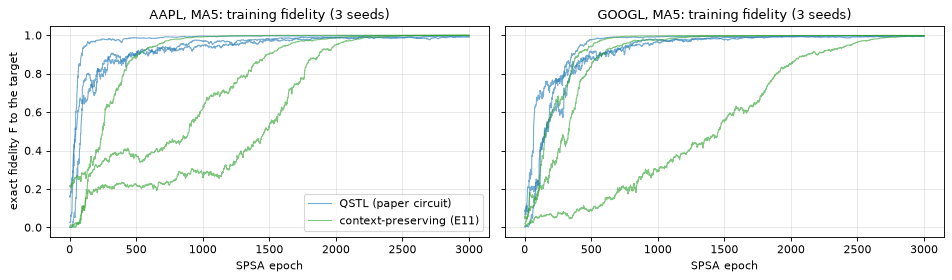

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
for ax, ticker in zip(axes, TICKERS):
    for name in ("QSTL (paper circuit)", "context-preserving (E11)"):
        for i, seed in enumerate(SEEDS):
            h = live_histories[(name, seed, ticker)]
            ax.plot(h["epoch"], h["fidelity"], color=COLORS[name], alpha=0.6, lw=1,
                    label=name if i == 0 else None)
    ax.set_title(f"{ticker}, MA5: training fidelity ({len(SEEDS)} seeds)")
    ax.set_xlabel("SPSA epoch")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("exact fidelity F to the target")
axes[0].legend(loc="lower right")
plt.tight_layout()
plt.show()

**Observation.** Both circuits drive the training fidelity close to 1 within
3000 epochs, using the paper's optimizer and shot budget. The 32-parameter
paper circuit rises fastest. The 4-parameter context-preserving circuit needs
anywhere from a few hundred to about 2500 epochs, depending on the seed: the
random start is far from the solution and SPSA with constant gains moves
slowly on a flat loss.

**Inference.** The QBGU training procedure works as described: the circuit
learns to map the superposed input onto the target state.

## 7. Headline reproduction result

### 7.1 Joint readout: the paper's Fig. 13 and Table 1

First the paper's own view: the measured distribution of the full output
state against the target (seed 42).

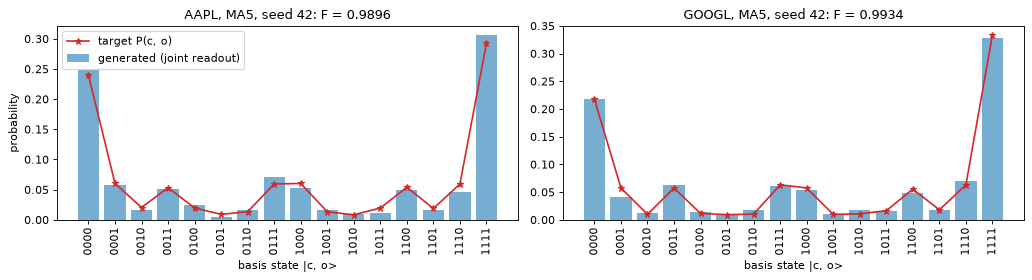

mean                         std         
kl_definition        kl_conditional_sum kl_joint kl_conditional_sum kl_joint
asset model paper_kl                                                        
AAPL  MTL   0.0614               3.7811   1.1061             3.0708   0.7103
      STL   0.1047               0.0070   0.0014             0.0026   0.0006
GOOGL MTL   0.0754               1.4231   0.4066             1.1277   0.2813
      STL   0.1239               0.0107   0.0027             0.0044   0.0011

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
states = [format(i, "04b") for i in range(16)]
for ax, ticker in zip(axes, TICKERS):
    task, circuit = live_circuits[("QSTL (paper circuit)", 42, ticker)]
    ax.bar(range(16), task.output_joint(circuit).reshape(-1), color=COLORS["QSTL (paper circuit)"], alpha=0.6,
           label="generated (joint readout)")
    ax.plot(range(16), task.joint.reshape(-1), "*-", color=COLORS["target"], label="target P(c, o)")
    ax.set_xticks(range(16), states, rotation=90)
    ax.set_xlabel("basis state |c, o>")
    ax.set_title(f"{ticker}, MA5, seed 42: F = {task.fidelity(circuit):.4f}")
axes[0].set_ylabel("probability")
axes[0].legend()
plt.tight_layout()
plt.show()

table1 = pd.read_csv(RESULTS / "paper_figures" / "table1_kl.csv")
table1 = table1[(table1.readout == "output") & table1.kl_definition.isin(["kl_joint", "kl_conditional_sum"])]
table1.pivot_table(index=["asset", "model", "paper_kl"], columns="kl_definition", values=["mean", "std"]).round(4)

**Observation.** The joint readout matches the target closely, as in the
paper's Fig. 13. For Table 1 (raw data, stored S4 runs,
`results/paper_figures/table1_kl.csv`) our STL values are lower than the
paper's 0.10–0.12. Our MTL values are higher than our STL values, while the
paper reports the opposite.

**Inference.** The fit of the joint distribution, the core of QBGU, is
reproduced. The Table 1 numbers cannot be compared directly: the paper does
not define which KL it reports, and the data differ. The MTL-vs-STL ordering
is a qualitative difference and is examined in §8.

**Claim impact.** C1 (joint fit): reproduced qualitatively. Table 1 values:
not comparable (`INCOMPARABLE`).

### 7.2 Per-context readout: predicting a new day

Now use the same trained circuits the way a prediction is made: one context
in, read the prediction qubit.

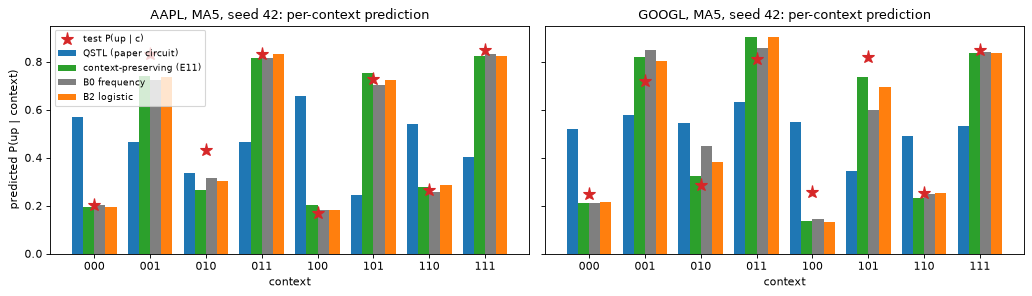

mean context retention       
                                                  mean    std
model                    ticker                              
QSTL (paper circuit)     AAPL                    0.124  0.005
                         GOOGL                   0.177  0.021
context-preserving (E11) AAPL                    1.000  0.000
                         GOOGL                   1.000  0.000

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
width = 0.2
for ax, ticker in zip(axes, TICKERS):
    t = live_tasks[ticker]
    test_joint = joint_distribution(t.test_windows, 2, 2)
    series = {
        "QSTL (paper circuit)": live_circuits[("QSTL (paper circuit)", 42, ticker)],
        "context-preserving (E11)": live_circuits[("context-preserving (E11)", 42, ticker)],
    }
    for i, (name, (task, circuit)) in enumerate(series.items()):
        ax.bar(np.arange(8) + (i - 1.5) * width, task.inference_conditional(circuit)[:, 1], width, color=COLORS[name], label=name)
    for i, name in enumerate(("B0 frequency", "B2 logistic")):
        ax.bar(np.arange(8) + (i + 0.5) * width, live_circuits[(name, ticker)][:, 1], width, color=COLORS[name], label=name)
    ax.plot(range(8), test_joint[:, 1] / test_joint.sum(axis=1), "*", color=COLORS["target"], ms=12, label="test P(up | c)")
    ax.set_xticks(range(8), labels)
    ax.set_xlabel("context")
    ax.set_title(f"{ticker}, MA5, seed 42: per-context prediction")
axes[0].set_ylabel("predicted P(up | context)")
axes[0].legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()

retention_rows = []
for name in ("QSTL (paper circuit)", "context-preserving (E11)"):
    for seed in SEEDS:
        for ticker in TICKERS:
            task, circuit = live_circuits[(name, seed, ticker)]
            retention_rows.append({"model": name, "ticker": ticker, "mean context retention": context_retention(circuit).mean()})
pd.DataFrame(retention_rows).groupby(["model", "ticker"]).agg(["mean", "std"]).round(3)

**Observation.** The context-preserving circuit, B0 and B2 follow the test
$P(\text{up} \mid c)$ closely. The paper circuit, trained to $F \approx 0.99$,
gives per-context predictions that do not follow the context: its mean context
retention is close to the 0.125 of a fully mixed register, against exactly 1
for the context-preserving circuit.

**Inference.** The QBGU loss constrains the circuit only on the one superposed
input it is trained on. A circuit that also rotates the context qubits can
match the joint target while moving weight between contexts, so its
single-context output differs from what the joint fit suggests. This is a
property of the general-purpose ansatz combined with the batch loss, not of the
contextual idea: keeping the context register fixed (E11) removes it.

**Remaining uncertainty.** The paper's exact gate decomposition is inferred from
its parameter count; a decomposition that leaves the context register
untouched would behave like E11.

**Claim impact.** C1 for prediction: not confirmed with the paper-style ansatz in
our setting; the joint fit itself reproduces.

### 7.3 Multi-seed headline (stored sweep S4)

The same comparison over five seeds and both preprocessings, with the paired
95 % intervals recomputed here from the per-seed values and checked against
the Phase 5 table (`results/phase5/pairs.csv`).

In [11]:
s4 = pd.read_csv(RESULTS / "phase3_s4" / "metrics_long.csv")
pairs = pd.read_csv(RESULTS / "phase5" / "pairs.csv")


def per_seed(frame, candidate, model, metric="inference/test/log_loss"):
    rows = frame[(frame.candidate == candidate) & (frame.model == model) & (frame.metric == metric)]
    return rows.set_index(["asset", "seed"])["value"]


HEADLINE = [
    ("C1", "QSTL vs B0, raw", ("e3_qstl_original", "QSTL"), ("e3_baselines_classical", "B0_frequency")),
    ("C1", "QSTL vs B0, MA5", ("e3_qstl_ma5", "QSTL"), ("e3_baselines_ma5", "B0_frequency")),
    ("C1", "QSTL vs B3 31 params, MA5", ("e3_qstl_ma5", "QSTL"), ("e3_baselines_ma5", "B3_mlp_h6")),
    ("C2", "QMTL vs QSTL 2-layer, 250/asset, raw", ("e4_qmtl_original", "QMTL"), ("e3_qstl_l2_e250", "QSTL")),
    ("C2", "QMTL vs QSTL 2-layer, 250/asset, MA5", ("e4_qmtl_ma5", "QMTL"), ("e3_qstl_l2_e250_ma5", "QSTL")),
]
rows = []
for claim, label, candidate, reference in HEADLINE:
    a, b = per_seed(s4, *candidate), per_seed(s4, *reference)
    for asset in ("AAPL", "GOOGL"):
        diff = (a.loc[asset] - b.loc[asset]).dropna()
        mean, low, high = paired_interval(diff)
        stored_row = pairs[(pairs.label == label) & (pairs.asset == asset) & (pairs.role == "primary")].iloc[0]
        # The stored table uses a 3-decimal t quantile (2.776 for 4 d.o.f.), hence the tolerance on the bound.
        assert np.isclose(mean, stored_row.mean_difference, atol=1e-12) and abs(low - stored_row.ci95_low) < 1e-3
        rows.append({"claim": claim, "comparison": label, "asset": asset, "seeds": len(diff),
                     "candidate": a.loc[asset].mean(), "reference": b.loc[asset].mean(),
                     "difference": mean, "95% low": low, "95% high": high,
                     "reading": "not distinguishable" if low <= 0 <= high else ("higher" if low > 0 else "lower")})
headline = pd.DataFrame(rows)
headline

,claim,comparison,asset,seeds,candidate,reference,difference,95% low,95% high,reading
0,C1,"QSTL vs B0, raw",AAPL,5,0.7175,0.6956,0.0219,-0.0107,0.0544,not distinguishable
1,C1,"QSTL vs B0, raw",GOOGL,5,0.7058,0.6946,0.0112,-0.0067,0.0291,not distinguishable
2,C1,"QSTL vs B0, MA5",AAPL,5,0.7219,0.4750,0.2469,0.0991,0.3946,higher
3,C1,"QSTL vs B0, MA5",GOOGL,5,0.6849,0.5142,0.1707,0.1118,0.2295,higher
4,C1,"QSTL vs B3 31 params, MA5",AAPL,5,0.7219,0.4750,0.2469,0.0991,0.3946,higher
5,C1,"QSTL vs B3 31 params, MA5",GOOGL,5,0.6849,0.5142,0.1706,0.1118,0.2295,higher
6,C2,"QMTL vs QSTL 2-layer, 250/asset, raw",AAPL,5,0.7278,0.7142,0.0136,-0.0676,0.0948,not distinguishable
7,C2,"QMTL vs QSTL 2-layer, 250/asset, raw",GOOGL,5,0.8744,0.7393,0.1351,-0.3280,0.5983,not distinguishable
8,C2,"QMTL vs QSTL 2-layer, 250/asset, MA5",AAPL,5,0.7041,0.6989,0.0052,-0.1455,0.1560,not distinguishable
9,C2,"QMTL vs QSTL 2-layer, 250/asset, MA5",GOOGL,5,0.6848,0.7191,-0.0343,-0.0977,0.0291,not distinguishable


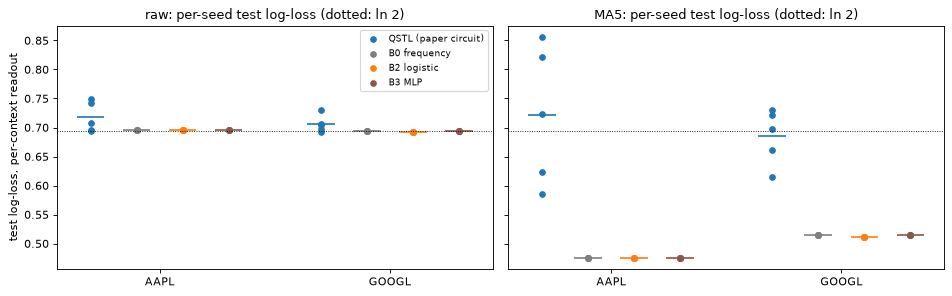

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, setting, qstl, base in ((axes[0], "raw", "e3_qstl_original", "e3_baselines_classical"),
                                (axes[1], "MA5", "e3_qstl_ma5", "e3_baselines_ma5")):
    series = [("QSTL (paper circuit)", per_seed(s4, qstl, "QSTL")),
              ("B0 frequency", per_seed(s4, base, "B0_frequency")),
              ("B2 logistic", per_seed(s4, base, "B2_logistic")),
              ("B3 MLP", per_seed(s4, base, "B3_mlp_h6"))]
    for j, asset in enumerate(("AAPL", "GOOGL")):
        for i, (name, values) in enumerate(series):
            x = j * 5 + i
            ax.scatter(np.full(5, x), values.loc[asset].values, color=COLORS[name], s=25,
                       label=name if j == 0 else None)
            ax.hlines(values.loc[asset].mean(), x - 0.3, x + 0.3, color=COLORS[name])
    ax.axhline(np.log(2), color="black", ls=":", lw=0.8)
    ax.set_xticks([1.5, 6.5], ["AAPL", "GOOGL"])
    ax.set_title(f"{setting}: per-seed test log-loss (dotted: ln 2)")
axes[0].set_ylabel("test log-loss, per-context readout")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

**Observation.** Every seed is shown. On raw data all models sit at $\ln 2$
and the paper circuit is not distinguishable from B0. On MA5 the classical
models reach 0.47–0.51 with almost no seed spread, while the paper circuit's
per-context readout is higher (0.59–0.86) and varies with the seed. QMTL and a
QSTL of equal size and budget are not distinguishable (wide intervals).

**Inference.** In our setting the per-context prediction of the paper-style
circuit does not reach the classical references, and the multi-task
architecture gives no measurable gain over single-task training at matched
size.

**Remaining uncertainty.** Five seeds; QMTL intervals up to ±0.46 wide; the
QMTL parameter split is inferred from the paper's counts.

**Claim impact.** C1 (prediction) and C2: not confirmed in our setting.

## 8. Comparison with classical baselines

The paper evaluates its quantum models on their own and does not include a
classical reference, so the references below were planned before the runs
(Phase 1) and the decision rule was frozen before the comparison table was
generated (`LOG.md`, "Phase 5 Comparison Plan").

**What is and is not matched** (paper circuit vs baselines):

| Dimension | Status |
|---|---|
| Information and inputs | matched: the same $T$ context symbols, nothing else |
| Training data | matched: the same chronological training windows |
| Parameter count | matched where stated: B3 (31) vs QSTL (32); B2 (4) vs E11 (4); B0 (8) is the exact maximum-likelihood table |
| Optimization steps | not matched: quantum 3000 SPSA epochs with shot noise; baselines full-batch Adam / closed form |
| Tuning budget | not matched: baselines choose regularization on a validation split; quantum models use the paper's fixed hyperparameters (no tuning, as in the paper) |
| Compute and wall time | not matched, reported only (`results/phase5/systems.csv`); no speed claim is tested |
| Evaluation protocol | matched: the same test windows, the same per-context readout, the same metric, final checkpoint |

The tuning asymmetry favours the baselines slightly, but B0 has no
hyperparameter that matters at these sample sizes, and it is the reference
for most claims.

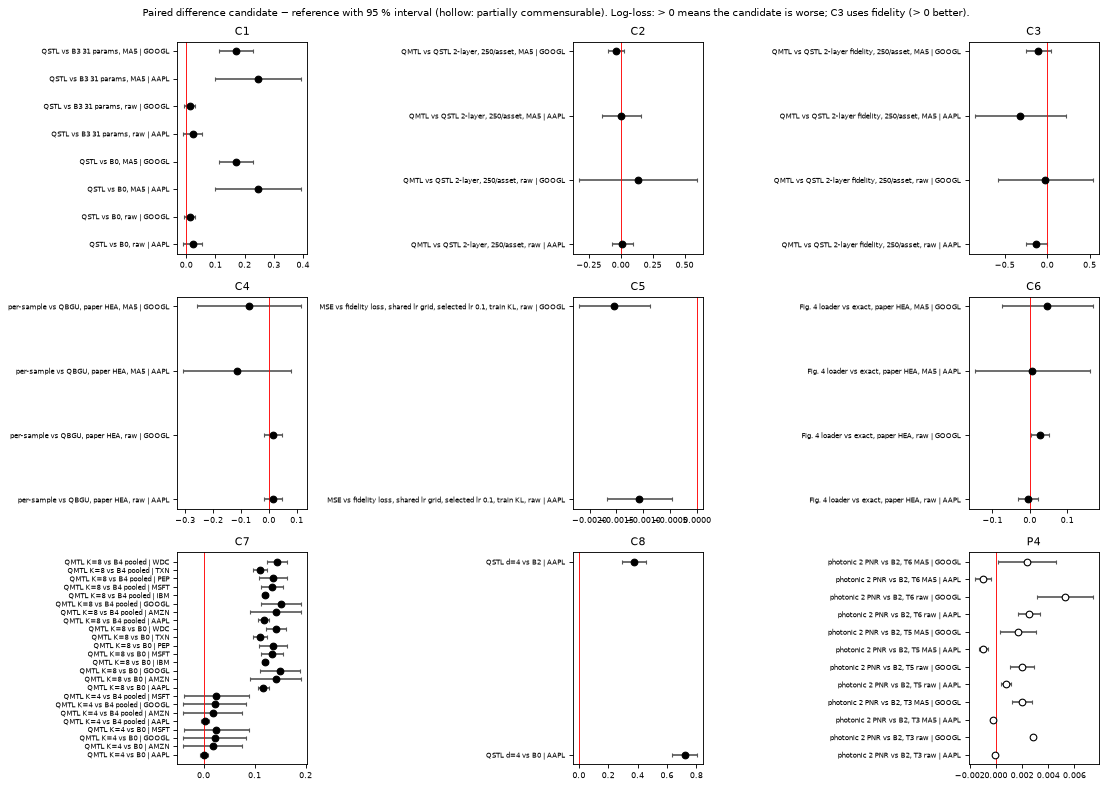

,claim,kind,reported,reason
0,C1,parity,UNSUPPORTED,4 of 8 primary cells against the claim
1,C2,advantage,UNSUPPORTED,no advantage in any of 4 primary cells (all no...
2,C3,advantage,UNSUPPORTED,"opposite direction in 1 of 4 primary cells, ad..."
3,C4,parity,UNSUPPORTED (rule output SUPPORTED; see LOG am...,no primary cell against the claim (4 cells)
4,C5,advantage,UNSUPPORTED,"opposite direction in 2 of 2 primary cells, ad..."
5,C6,parity,UNSUPPORTED,1 of 4 primary cells against the claim
6,C7,parity,UNSUPPORTED,16 of 24 primary cells against the claim
7,C8,parity,UNSUPPORTED,2 of 2 primary cells against the claim
8,P4,advantage,UNRESOLVED,primary pair confounded both ways: the photoni...
9,C9,robustness,UNRESOLVED,EVIDENCE_MISSING: E10 noise study not implemen...


In [13]:
primary = pairs[pairs.role == "primary"].copy()
claim_order = ["C1", "C2", "C3", "C4", "C5", "C6", "C7", "C8", "P4"]
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
for ax, claim in zip(axes.flat, claim_order):
    rows = primary[primary.claim == claim].reset_index(drop=True)
    y = np.arange(len(rows))
    hollow = rows.status != "COMMENSURABLE"
    ax.errorbar(rows.mean_difference, y, xerr=[rows.mean_difference - rows.ci95_low, rows.ci95_high - rows.mean_difference],
                fmt="none", ecolor="#555555", capsize=2)
    ax.scatter(rows.mean_difference[~hollow], y[~hollow], color="black", zorder=3)
    ax.scatter(rows.mean_difference[hollow], y[hollow], facecolors="white", edgecolors="black", zorder=3)
    ax.axvline(0, color="red", lw=0.8)
    ax.set_yticks(y, [f"{l} | {a}" for l, a in zip(rows.label, rows.asset)], fontsize=6)
    ax.set_title(claim, fontsize=10)
    ax.tick_params(axis="x", labelsize=7)
fig.suptitle("Paired difference candidate − reference with 95 % interval (hollow: partially commensurable). "
             "Log-loss: > 0 means the candidate is worse; C3 uses fidelity (> 0 better).", fontsize=9)
plt.tight_layout()
plt.show()

claims = pd.read_csv(RESULTS / "phase5" / "claims.csv")
claims["reported"] = claims.outcome
claims.loc[claims.claim == "C4", "reported"] = "UNSUPPORTED (rule output SUPPORTED; see LOG amendment 2026-11-25T03:55Z)"
c5_verdict = json.loads((RESULTS / "phase5_c5" / "verdict.json").read_text(encoding="utf-8"))
assert claims.loc[claims.claim == "C5", "outcome"].item() == c5_verdict["outcome"]  # Phase 5 table and C5 grid agree
claims[["claim", "kind", "reported", "reason"]]

**Observation.** The only intervals below 0 against a classical reference are
three photonic cells (P4), lower than B2 by at most 0.001 nats; no gate-model
comparison favours the quantum model.
Where the per-context readout has signal to work with (MA5, $K = 8$, $d = 4$),
the classical references are lower.

**Inference.** On this data and protocol the comparative claims are not
confirmed. The labels in the table are the outcome labels of the
reproduction workflow; they describe this setting, not the paper as a whole.

**Remaining uncertainty.** C4's rule output was `SUPPORTED` because both arms
sit near chance on the primary cells; it is reported as not confirmed on the
gradient evidence in §9 (a dated amendment in `LOG.md`). The C5 panel above
is the shared learning-rate grid at the selected lr, explained in §9.3. The
QMTL multi-task control is pooled shrinkage (B4) only.

## 9. Controls and ablations

Each control separates the paper's explanation from a credible alternative.

### 9.1 Is it the batch loss or the ansatz? (context retention, extension E11)

If the gap in §7.2 came from QBGU itself, a circuit that keeps the context
would also fail. Stored context retention of the paper circuit
(`results/phase3_s1/context_retention.csv`) and the live E11 results:

In [14]:
retention = pd.read_csv(RESULTS / "phase3_s1" / "context_retention.csv")
retention = retention[retention.candidate.isin(["e3_qstl_original", "e3_qstl_ma5"])]
summary = retention.groupby(["candidate", "asset", "seed"]).p_context_kept.mean().groupby(["candidate", "asset"]).agg(["mean", "std"])
display(summary.round(3))

e11 = live[live.model.isin(["context-preserving (E11)", "B2 logistic", "B0 frequency"])]
e11.groupby(["model", "ticker"])[["parameters", "test log-loss"]].mean().round(4)

mean    std
candidate        asset              
e3_qstl_ma5      AAPL   0.118  0.018
                 GOOGL  0.142  0.031
e3_qstl_original AAPL   0.129  0.022
                 GOOGL  0.131  0.030

parameters  test log-loss
model                    ticker                           
B0 frequency             AAPL           8.0         0.4750
                         GOOGL          8.0         0.5142
B2 logistic              AAPL           4.0         0.4753
                         GOOGL          4.0         0.5120
context-preserving (E11) AAPL           4.0         0.4760
                         GOOGL          4.0         0.5097

**Observation.** The paper circuit keeps a context with probability 0.12–0.15
(0.125 is a fully mixed 3-qubit register). Trained with the same QBGU loss and
optimizer, the 4-parameter context-preserving circuit comes within 0.005 nats
of the test log-loss of B2 logistic regression (4 parameters) and B0.

**Inference.** QBGU can train a predictor; the gap comes from the general
ansatz acting on the context register. The predictor it then learns is
$q(\text{up} \mid c) = \sin^2(a_c/2)$ with $a_c$ linear in the bits: a
logistic-type additive model with a different link function, which explains
why it performs on par with B2 rather than better.

### 9.2 Does QBGU equal full-batch SGD? (C4, Eq. 18–20)

The paper argues that one QBGU step equals a full batch of per-sample steps.
Control: compare the QBGU gradient with the per-sample objective's gradient at
the same parameters (20 random draws, `results/e5_qbgu_gradient/`), and compare
the optima of the two objectives.

In [15]:
gradients = pd.read_csv(RESULTS / "e5_qbgu_gradient" / "gradient_comparison.csv")
display(gradients.groupby(["data", "ansatz"])[["cos_F_vs_J_basis", "cos_F_vs_J_cond"]].agg(["mean", "min", "max"]).round(3))
display(pd.read_csv(RESULTS / "e5_qbgu_gradient" / "objective_optima.csv").round(4))
pairs[(pairs.claim == "C4") & (pairs.role == "secondary")][["label", "asset", "mean_difference", "ci95_low", "ci95_high", "candidate_vs_reference"]]

cos_F_vs_J_basis               cos_F_vs_J_cond              
                                                mean    min    max            mean    min    max
data ansatz                                                                                     
MA5  HEA 4 layers (32)                         0.041 -0.471  0.570           0.040 -0.428  0.614
     context-preserving order 1 (4)            0.210 -0.975  0.951           0.476 -0.990  0.990
     context-preserving order 3 (8)            0.309 -0.967  0.998           0.467 -0.960  0.984
raw  HEA 4 layers (32)                        -0.022 -0.358  0.330           0.009 -0.280  0.311
     context-preserving order 1 (4)           -0.181 -0.879  0.769           0.031 -0.917  0.999
     context-preserving order 3 (8)           -0.184 -0.845  0.808          -0.024 -0.757  0.752

,data,predictor,F_batch,J_basis,J_cond
0,raw,true conditional q = p,1.0000,0.5013,1.0000
1,raw,argmax predictor,0.5172,0.5174,0.5174
2,MA5,true conditional q = p,1.0000,0.6806,1.0000
3,MA5,argmax predictor,0.7971,0.7976,0.7976


,label,asset,mean_difference,ci95_low,ci95_high,candidate_vs_reference
44,"per-sample batch 10,000 vs QBGU, context-prese...",AAPL,0.4327,0.0078,0.8577,higher
45,"per-sample batch 10,000 vs QBGU, context-prese...",GOOGL,0.6259,0.3625,0.8893,higher
46,"per-sample batch 10,000 vs QBGU, context-prese...",AAPL,0.6217,0.4398,0.8036,higher
47,"per-sample batch 10,000 vs QBGU, context-prese...",GOOGL,0.8493,0.3074,1.3912,higher


**Observation.** For the paper circuit, the cosine between the two gradients
averages about 0 (range −0.47 to +0.61). For context-preserving circuits it
varies across draws from −0.99 to +0.99, so the two gradients do not point in
the same direction in general. The
optima differ: the QBGU fidelity is maximized by the calibrated conditional
$q = p$, the per-sample (one-hot) fidelity by the argmax predictor. With a
context-preserving circuit, per-sample training ends 0.43–0.85 nats higher in
test log-loss (overconfident) while reaching the same accuracy.

**Inference.** In our implementation the two procedures optimize different
objectives; QBGU behaves like a calibrated (Hellinger-type) classical loss.
**Claim impact.** C4: not confirmed.

### 9.3 Trained loader (C6) and MSE vs fidelity loss (C5)

In [16]:
loader = pd.read_csv(RESULTS / "phase3_s9" / "s9_loader_states.csv")
display(loader.groupby("asset")[["tvd", "fidelity_magnitudes_only", "fidelity_to_exact_state"]].agg(["mean", "min", "max"]).round(3))
pairs[pairs.claim == "C6"][["role", "label", "asset", "mean_difference", "ci95_low", "ci95_high", "status"]]

tvd               fidelity_magnitudes_only           fidelity_to_exact_state              
        mean    min    max                     mean  min  max                    mean    min    max
asset                                                                                              
AAPL   0.003  0.002  0.005                      1.0  1.0  1.0                   0.212  0.003  0.569
GOOGL  0.004  0.002  0.006                      1.0  1.0  1.0                   0.248  0.006  0.541

,role,label,asset,mean_difference,ci95_low,ci95_high,status
54,primary,"Fig. 4 loader vs exact, paper HEA, raw",AAPL,-0.0056,-0.0320,0.0209,COMMENSURABLE
55,primary,"Fig. 4 loader vs exact, paper HEA, raw",GOOGL,0.0282,0.0040,0.0524,COMMENSURABLE
56,primary,"Fig. 4 loader vs exact, paper HEA, MA5",AAPL,0.0067,-0.1479,0.1613,COMMENSURABLE
57,primary,"Fig. 4 loader vs exact, paper HEA, MA5",GOOGL,0.0466,-0.0754,0.1685,COMMENSURABLE
58,secondary,"Fig. 4 loader vs exact, context-preserving, raw",AAPL,0.4101,-0.1040,0.9243,COMMENSURABLE
59,secondary,"Fig. 4 loader vs exact, context-preserving, raw",GOOGL,1.0783,0.4642,1.6924,COMMENSURABLE
60,secondary,"Fig. 4 loader vs exact, context-preserving, MA5",AAPL,0.5364,0.0527,1.0202,COMMENSURABLE
61,secondary,"Fig. 4 loader vs exact, context-preserving, MA5",GOOGL,0.1245,0.0347,0.2142,COMMENSURABLE


**Observation.** The trained HEA loader reproduces the context probabilities
(TVD 0.002–0.006, as in the paper's Fig. 11), but its amplitudes' phases are
not fixed by the MSE loss on probabilities: fidelity to the exact state ranges
from 0.00 to 0.57. With the paper circuit this hardly matters (it can undo
phases); with a context-preserving circuit it raises the test log-loss by up
to 1.08.

**Claim impact.** C6: probabilities reproduced, state preparation not
confirmed.

**C5, MSE vs fidelity loss.** The paper trains MSE with lr $10^{-5}$ and the
fidelity loss with lr 0.1, so Fig. 17 mixes the loss with the step size.
Control (planned in Phase 1, decision rule fixed before the runs): both losses
on the same SPSA grid $\{10^{-5}, 10^{-3}, 10^{-2}, 10^{-1}, 1\}$, 10,000
epochs, raw data, 5 seeds (50 runs, `results/phase5_c5/`). Per loss, the
learning rate is chosen on the training metric only.

lr                                    1.0000e-05  1.0000e-03  1.0000e-02  1.0000e-01  1.0000e+00
metric                asset loss                                                                
final_fidelity        AAPL  MSE           0.0614      0.0664      0.0760      0.0724      0.0804
                            fidelity      0.0638      0.5252      0.9983      0.9990      0.0415
                      GOOGL MSE           0.0811      0.0844      0.0400      0.0987      0.0735
                            fidelity      0.0495      0.5533      0.9978      0.9985      0.0611
output/train/kl_joint AAPL  MSE           0.6884      0.2182      0.0037      0.0000      0.1319
                            fidelity      0.6897      0.4637      0.0021      0.0011      0.5011
                      GOOGL MSE           0.4724      0.1628      0.0027      0.0001      0.1248
                            fidelity      0.4273      0.4426      0.0031      0.0016      0.5174

,asset,comparison,mse_lr,fidelity_lr,mean_difference,ci95_low,ci95_high,fidelity_vs_mse
0,AAPL,selected lr per loss,1.0000e-01,0.1,0.0011,0.0005,0.0017,higher
2,AAPL,"paper lrs (MSE 1e-5, fidelity 0.1)",1.0000e-05,0.1,-0.6873,-1.0077,-0.3669,lower
4,GOOGL,selected lr per loss,1.0000e-01,0.1,0.0015,0.0009,0.0022,higher
6,GOOGL,"paper lrs (MSE 1e-5, fidelity 0.1)",1.0000e-05,0.1,-0.4708,-0.6469,-0.2948,lower


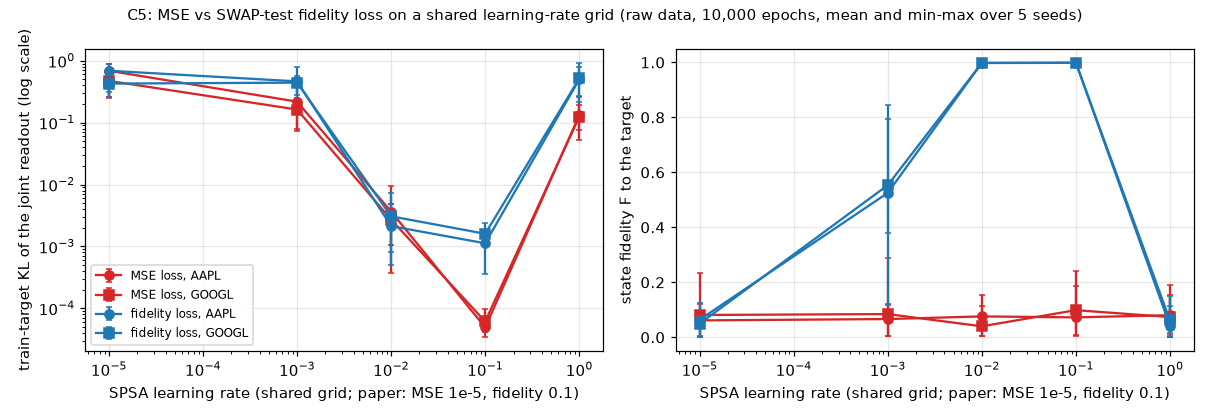

C5 outcome by the frozen rule: UNSUPPORTED


In [17]:
c5 = pd.read_csv(RESULTS / "phase5_c5" / "aggregate.csv")
display(c5[c5.metric.isin(["output/train/kl_joint", "final_fidelity"])]
        .pivot_table(index=["metric", "asset", "loss"], columns="lr", values="mean").round(4))
c5_pairs = pd.read_csv(RESULTS / "phase5_c5" / "pairs.csv")
display(c5_pairs[c5_pairs.metric == "output/train/kl_joint"]
        [["asset", "comparison", "mse_lr", "fidelity_lr", "mean_difference", "ci95_low", "ci95_high", "fidelity_vs_mse"]])
display(Image(filename=str(RESULTS / "phase5_c5" / "fig_c5_lr_grid.png"), width=900))
print("C5 outcome by the frozen rule:", c5_verdict["outcome"])

**Observation.** At the paper's learning rates the gap of Fig. 17 reproduces
(fidelity lower in train KL by 0.47–0.69). On the shared grid both losses pick
lr 0.1, and there MSE reaches a slightly *lower* train KL than the fidelity
loss (by 0.0011 and 0.0015, intervals excluding 0). Only the fidelity loss
also prepares the target state ($F \approx 0.999$); MSE stays at
$F \approx 0.07$ at every learning rate, because it sees measured
probabilities only, like the loader above.

**Inference.** The "MSE fails" result comes from MSE's learning rate, not from
the loss. The fidelity loss has a real advantage only where the phases of the
state matter, which is not the case for the measured distribution of Fig. 17.

**Claim impact.** C5: not confirmed on a shared learning-rate grid
(`UNSUPPORTED` by the frozen rule); the paper's figure reproduces at its own
settings.

### 9.4 Multi-step and larger circuits (extensions E14, S10–S12)

Not in the paper. Up to 10 qubits, with and without interference between
predicted paths, and with L-BFGS on the shot-free loss: the circuit without
interference equals logistic regression to three decimals, and the
interfering circuit is equal or worse in every cell
(`results/phase3_s10`, `results/phase3_s11`, `results/phase3_s12`).

## 10. Robustness and uncertainty

### 10.1 Training-set size (extension, sweep S3)

A quantum inductive bias, if present, should show most at small data. Stored
sweep S3: training sets from 25 windows to the full history, 10 seeds each.

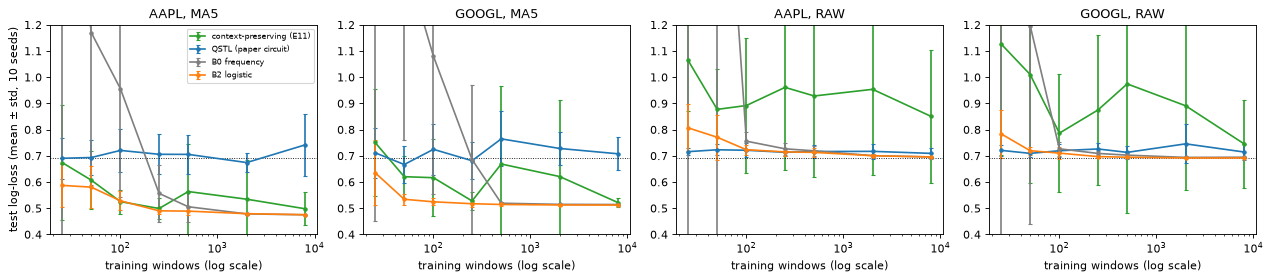

In [18]:
sizes = pd.read_csv(RESULTS / "phase3_s3" / "size_curves.csv")
series = {
    "context-preserving (E11)": "e11_qstl_cc1:QSTL",
    "QSTL (paper circuit)": "e3_qstl_original:QSTL",
    "B0 frequency": "e3_baselines_classical:B0_frequency",
    "B2 logistic": "e3_baselines_classical:B2_logistic",
}
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
for ax, (data, asset) in zip(axes, [(d, a) for d in ("ma5", "raw") for a in ("AAPL", "GOOGL")]):
    for name, model in series.items():
        rows = sizes[(sizes.model == model) & (sizes.data == data) & (sizes.asset == asset)].sort_values("train_size")
        ax.errorbar(rows.train_size, rows["mean"], yerr=rows["std"], color=COLORS[name], marker="o", ms=3, capsize=2,
                    label=name)
    ax.set_xscale("log")
    ax.axhline(np.log(2), color="black", ls=":", lw=0.8)
    ax.set_title(f"{asset}, {data.upper()}")
    ax.set_xlabel("training windows (log scale)")
    ax.set_ylim(0.4, 1.2)
axes[0].set_ylabel("test log-loss (mean ± std, 10 seeds)")
axes[0].legend(fontsize=7)
plt.tight_layout()
plt.show()

**Observation.** On MA5 the context-preserving circuit follows B2 logistic
regression at most sizes; at small sizes both stay below the frequency table
B0, which overfits. The circuit is never below B2 and is above it in 7 of 28
cells, with a wider seed spread. On raw data its SPSA runs vary strongly
between seeds and stay above $\ln 2$. The paper circuit's per-context readout
stays near or above $\ln 2$ at every size.

**Inference.** No small-data advantage appears. Where it trains well, the
circuit behaves like the classical model it is mathematically close to. Its
seed spread comes from shot-noise SPSA; the shot-free context-preserving runs
of the extension sweeps S11–S12 have almost no seed variance.

### 10.2 Sources of uncertainty

* Seeds: 5 per configuration (S3: 10); individual values are shown in §7.3.
* Raw-data comparisons sit at $\ln 2$ and are uninformative; conclusions rest
  on MA5, $K = 8$ and $d = 4$.
* Shot noise: SPSA uses 10,000 shots per loss evaluation, as in the paper;
  shot-free L-BFGS runs (S12) give the same conclusions.
* The Phase 5 decision rule, sweep completeness (1900 of 1900 runs) and
  the commensurability of each pair are recorded in `results/phase5/`.

In [19]:
pd.read_csv(RESULTS / "phase5" / "coverage.csv")[["sweep", "machine", "expected_runs", "completed_runs", "complete"]]

,sweep,machine,expected_runs,completed_runs,complete
0,S1,remote Linux machine,80,80,True
1,S2,remote Linux machine,50,50,True
2,S3,remote Linux machine,560,560,True
3,S4,remote Linux machine,50,50,True
4,S5,remote Linux machine,45,45,True
5,S6,remote Linux machine,60,60,True
6,S7,remote Linux machine,50,50,True
7,S8,remote Linux machine,50,50,True
8,S9,remote Linux machine,70,70,True
9,S10,remote Linux machine,120,120,True


## 11. Photonic adaptation (MerLin)

Status `PARTIAL_MERLIN_TRANSLATION`: an **adaptation**, not the paper's method.
QBGU needs a superposed input with data-defined amplitudes, which is not an
available linear-optics operation, so only the prediction task of C1 is
translated: $q(\text{up} \mid c)$.

**Model.** $T + 1$ modes; trainable interferometer, phases $\pi c_i$ on modes
$1..T$, interferometer, the same phases again, interferometer. Two photons
enter (`[1,0,1,0]` for $T = 3$). $q(\text{up} \mid c)$ is the probability that
the detector on mode 0 clicks. Trained on the count-weighted log-likelihood
(the objective of B2) with Adam, exact simulation, exact gradients.

Live: the configuration of `configs/p4_photonic_n2_fock_ma5_merlin.json`
(2 indistinguishable photons, photon-number-resolving detection), seed 42.

In [20]:
photonic_cfg = config("p4_photonic_n2_fock_ma5_merlin.json")
start = time.time()
photonic_rows = []
for ticker in TICKERS:
    t = live_tasks[ticker]
    result = fit_photonic_model(counts_table(t.train_windows, 2, 2), photonic_cfg["photonic"], 42, torch.float64,
                                f"photonic_{ticker}", [])
    test = sequence_metrics(t.test_windows, 2, result["conditional"])
    photonic_rows.append({"model": "photonic (MerLin)", "ticker": ticker, "parameters": result["n_params"],
                          "input state": result["input_state"], "test log-loss": test["log_loss"],
                          "test accuracy": test["accuracy"]})
print(f"photonic training: {time.time() - start:.0f} s")
reference = live[(live.seed == 42) & live.model.isin(["B0 frequency", "B2 logistic", "context-preserving (E11)"])]
pd.concat([pd.DataFrame(photonic_rows), reference[["model", "ticker", "parameters", "test log-loss", "test accuracy"]]])

photonic training: 51 s


,model,ticker,parameters,input state,test log-loss,test accuracy
0,photonic (MerLin),AAPL,36,"[1, 0, 1, 0]",0.4751,0.8150
1,photonic (MerLin),GOOGL,36,"[1, 0, 1, 0]",0.5134,0.7938
6,context-preserving (E11),AAPL,4,NaN,0.4759,0.8150
7,context-preserving (E11),GOOGL,4,NaN,0.5121,0.7938
12,B0 frequency,AAPL,8,NaN,0.4750,0.8150
13,B2 logistic,AAPL,4,NaN,0.4753,0.8150
15,B0 frequency,GOOGL,8,NaN,0.5142,0.7938
16,B2 logistic,GOOGL,4,NaN,0.5120,0.7938


In [21]:
p1 = pd.read_csv(RESULTS / "phase4_p1" / "aggregate.csv")
p1_table = p1.pivot_table(index=["size", "preprocessing", "ticker"], columns="model",
                          values="inference/test/log_loss/mean").round(4)
display(p1_table)
p1_pairs = pd.read_csv(RESULTS / "phase4_p1" / "paired.csv")
p1_pairs = p1_pairs[p1_pairs.metric == "inference/test/log_loss"]
p1_pairs.assign(reading=np.where(~p1_pairs.excludes_zero, "not distinguishable",
                                 np.where(p1_pairs.mean_difference > 0, "higher", "lower"))) \
    .groupby(["comparison", "reading"]).size().unstack(fill_value=0)

model                      B0_frequency  B2_logistic      n1  n2_dist  n2_fock  n2_unbunched
size preprocessing ticker                                                                   
t3   ma5           AAPL          0.4750       0.4753  0.4752   0.4750   0.4750        0.4750
                   GOOGL         0.5142       0.5120  0.5130   0.5139   0.5140        0.5145
     raw           AAPL          0.6956       0.6957  0.6958   0.6956   0.6956        0.6957
                   GOOGL         0.6946       0.6918  0.6935   0.6946   0.6946        0.6946
t5   ma5           AAPL          0.4713       0.4723  0.4715   0.4715   0.4714        0.4713
                   GOOGL         0.5102       0.5006  0.5005   0.5021   0.5023        0.5084
     raw           AAPL          0.6974       0.6953  0.6959   0.6962   0.6961        0.6969
                   GOOGL         0.6952       0.6924  0.6952   0.6953   0.6944        0.6948
t6   ma5           AAPL          0.4737       0.4718  0.4706   0.4713   0.4707        0.4705
                   GOOGL         0.5108       0.4994  0.4998   0.5020   0.5018        0.5079
     raw           AAPL          0.7003       0.6953  0.6968   0.6974   0.6978        0.6979
                   GOOGL         0.7023       0.6924  0.6966   0.6981   0.6976        0.7002

reading,higher,lower,not distinguishable
comparison,,,
n1_vs_B0,1,7,4
n1_vs_B2,7,2,3
n2_dist_vs_B0,0,6,6
n2_dist_vs_B2,7,3,2
n2_fock_vs_B0,0,6,6
n2_fock_vs_B2,8,3,1
n2_fock_vs_n1,2,0,10
n2_fock_vs_n2_dist,0,2,10
n2_unbunched_vs_B0,1,6,5


**Hardware-aware settings (all P1 runs).** MerLin 0.4.2 / Perceval 1.3.1, exact
CPU simulation, no sampling (shot count n/a), no loss; modes 4 / 6 / 7 for
$T$ = 3 / 5 / 6; 2 photons (1-photon runs are an ablation); computation space
FOCK with photon-number-resolving detection, or UNBUNCHED with threshold
detection and collision-free postselection (keep rate 0.48–0.61); seeds 42–46.

**Observation.** The 2-photon model reaches the level of B2 logistic
regression within 0.006 nats in every cell, with 36–126 phases against 4–7
weights. Adding a second photon, or making the photons indistinguishable, does
not change the result measurably (10 of 12 cells not distinguishable).
Threshold detection is slightly worse than PNR in 4 cells.

**Inference.** The photonic model learns the same additive predictor; two-photon
interference adds no measurable benefit on this task.

**Claim impact.** Extension only. Photonic vs B2: `UNRESOLVED` by the rule,
since parameters and tuning are not matched; no advantage is observed.

## 12. Claim-level conclusion

Separate outcomes:

| Question | Answer | Evidence |
|---|---|---|
| Does the software execute? | yes: live baselines match the stored sweep exactly; shot-sampled SPSA runs agree in distribution | §6 |
| Does QBGU fit the training target? | yes, $F \approx 0.99$–$0.999$ | §6, §7.1 |
| Does the paper's metric reproduce? | not comparable: KL definition and data differ | §7.1 |
| Does the paper's explanation survive controls? | the joint fit does; per-context prediction needs a context-preserving circuit | §7.2, §9.1 |
| Does the method beat a fair classical baseline? | no difference in its favour found in our setting | §7.3, §8, §10 |

**1. What reproduced**

* QBGU with the SWAP-test loss and SPSA fits the joint target distribution
  (Fig. 13 qualitatively; §6, §7.1).
* The trained loader reproduces the context probabilities (Fig. 11; §9.3).
* At the paper's learning rates, MSE training stays far from the target where
  the fidelity loss converges (Fig. 17; §9.3).

**2. What did not reproduce in our setting**

* Per-context prediction with the paper-style circuit (C1 for prediction; §7.2, §7.3).
* QMTL lower than QSTL at half the parameters (C2), and faster convergence (C3) (§7.3, §8).
* QMTL at 4 and 8 assets (C7) and the $d = 4$ alignment (C8) against classical references (§8).
* Equality of QBGU and full-batch SGD (C4; §9.2) and preparation of the full context state by the trained loader (C6; §9.3).
* An advantage of the fidelity loss over MSE for learning the distribution
  once both share a learning-rate grid (C5; §9.3).

**3. What remains unresolved**

* The Table 1 KL values, because the KL definition is not stated (§7.1).

**4. What was not attempted**

* C9, the noise study (Fig. 22); C10, theoretical. Original data and the
  authors' code were not available.

**5. Reproduction verdict**

The core mechanism of the paper reproduces; the comparative claims could not be
confirmed on public substitute data with an added held-out test protocol.
The best quantum models perform on par with a 4-to-31-parameter classical
model. The differences may depend on details not specified in the paper
(data window, KL definition, circuit decomposition).

**6. Extension and photonic verdict**

A context-preserving circuit (E11) makes QBGU a working predictor equivalent to
logistic regression with a $\sin^2$ link (§9.1, §10.1). The MerLin 2-photon
adaptation reaches the same level with more parameters; photon number and
indistinguishability do not change it (§11). No quantum or photonic advantage
is claimed.

### Limitations

* Substitute data; preprocessing per experiment and date ranges inferred.
* Circuit decompositions and the QMTL parameter split inferred from parameter counts.
* Five seeds per configuration; QMTL intervals are wide.
* Baselines are validation-tuned, the quantum models use the paper's fixed hyperparameters.
* B4 (pooled shrinkage) is the only multi-task classical control.
* C5 control on raw data and the paper circuit only; C9 not run; MerLin results simulated only (no QPU, loss or shot noise).
* The Phase 5 "parity" reading and the C4 and photonic outcomes were settled
  after the comparison table was generated (dated amendments in `LOG.md`).